# 02 · Fenómeno 1: ¿qué significa "calidad" en estos datos?
**Pregunta.** ¿Qué variables de calidad miden una condición física del rollo y cuáles son reglas que el sistema aplica sobre otras columnas?

**Por qué importa.** Si un defecto se genera comparando una medición con su tolerancia, predecirlo con esa misma medición es una tautología: el modelo solo redescubre la regla. Antes de elegir un resultado hay que saber qué etiquetas son reglas.

**Pasos**
1. Pasar los 5 bloques de defecto a formato largo.
2. Medir cuántos registros son automáticos y cuánto pesan en la retención.
3. Intentar reconstruir reglas automáticas con los resúmenes por rollo.
4. Leer lo que escribe el sistema en Observaciones.

## 0. Configuración
Importa `src/ternium.py`, donde viven la carga de datos y las reglas de limpieza. Basta con tener el repositorio clonado: los Excel ya vienen en `data/`.

In [ ]:
# Solo en Colab: clona el repo del equipo e instala dependencias. En local no hace nada.
# El token de GitHub del equipo se guarda una vez en Colab -> 🔑 Secrets con el nombre GITHUB_TOKEN
# (con "Notebook access" activado). Si no está, lo pide aquí sin mostrarlo.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if not os.path.exists(REPO):
        try:
            from google.colab import userdata
            token = userdata.get('GITHUB_TOKEN')
        except Exception:
            from getpass import getpass
            token = getpass('Pega el token de GitHub del equipo: ')
        url = f'https://{token.strip()}@github.com/DiegoLarrieta/Entregable_Reto.git'
        r = subprocess.run(['git', 'clone', '-q', url, REPO], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError('No se pudo clonar el repo: revisa que el token sea el correcto y no haya expirado.')
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [1]:
# Configuración: busca la carpeta del repo para poder importar src/ternium.py.
import sys
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ternium import *

estilo()
pd.set_option('display.max_columns', 20)

In [2]:
df = aplicar_reglas(cargar_mc4())
D = defectos_largo(df)   # un renglón por defecto registrado
print(f'{len(df):,} rollos · {len(D):,} registros de defecto')

149,734 rollos · 295,086 registros de defecto


## 1. Cifras generales y relación Dictamen-Resolución

In [3]:
print(f"Rollos con al menos un defecto: {df['Defecto (1)'].notna().mean():.1%}")
print(f"Rollos RETENIDOS:               {(df.Dictamen == 'RETENIDO').mean():.1%}")
print(f"Registros de defecto automáticos: {D.a.mean():.1%}")
pd.crosstab(df.Dictamen, df['Resolución'])

Rollos con al menos un defecto: 88.5%
Rollos RETENIDOS:               50.2%
Registros de defecto automáticos: 76.0%


Resolución,CALIDAD DE PLANTA,CON OBSERVACIONES,CONSULTA A IP,POR PROGRAMACION,SOBRE ORDEN
Dictamen,,,,,
ACEPTADO,0,57351,0,0,17201
RETENIDO,70200,0,3799,1183,0


**Qué vemos.** Casi 9 de cada 10 rollos tienen algún defecto y la mitad queda retenida, lo que no puede significar que la mitad del acero sea malo. Tres de cada cuatro registros los genera el sistema. La tabla muestra que **Resolución no es una medida aparte**: cada resolución pertenece a un solo dictamen (ACEPTADO = con observaciones o sobre orden; RETENIDO = calidad de planta, consulta a IP o por programación).

## 2. ¿Quién retiene al rollo: una regla o un inspector?

In [4]:
# Rollos donde al menos un defecto que retiene viene de una regla (a = 1) o de un inspector (a = 0).
por_regla = set(D.loc[D.ret & (D.a == 1), 'row'])
por_inspector = set(D.loc[D.ret & (D.a == 0), 'row'])
ret = pd.DataFrame({'regla': df.index.isin(list(por_regla)),
                    'inspector': df.index.isin(list(por_inspector))})[df.Dictamen.eq('RETENIDO').values]
print(f"Retenidos con al menos una regla automática que retiene: {ret.regla.mean():.0%}")
print(f"Retenidos SOLO por reglas automáticas:                   {(ret.regla & ~ret.inspector).mean():.0%} ({(ret.regla & ~ret.inspector).sum():,} rollos)")

Retenidos con al menos una regla automática que retiene: 92%
Retenidos SOLO por reglas automáticas:                   81% (60,850 rollos)


**Qué vemos.** En 8 de cada 10 rollos retenidos, ningún inspector marcó un defecto que retenga: la retención viene solo de reglas automáticas. El Dictamen mide sobre todo **cumplimiento de especificación**, no una condición física observada.

## 3. Prueba de tautología
Si la regla del sistema fuera "el promedio del rollo está fuera de tolerancia", la etiqueta y nuestra reconstrucción coincidirían casi siempre.

In [5]:
espesor_fuera = (df.Espesor < df['Espesor Mínimo']) | (df.Espesor > df['Espesor Máximo'])
temp_baja = df['Temp Enrollado Real'] < df['Temp Enrollado Min']

print(pd.crosstab(tiene_defecto(df, 'ESPESOR (+/-)'), espesor_fuera,
                  rownames=['etiqueta ESPESOR (+/-)'], colnames=['promedio fuera de tolerancia']), '\n')
print(pd.crosstab(tiene_defecto(df, 'TEMPERATURA DE ENROLLADO (-)'), temp_baja,
                  rownames=['etiqueta TEMP. ENROLLADO (-)'], colnames=['real < mínimo']))

promedio fuera de tolerancia  False  True 
etiqueta ESPESOR (+/-)                    
False                         83131    441
True                          66151     11 

real < mínimo                  False  True 
etiqueta TEMP. ENROLLADO (-)               
False                         101948   1351
True                           45463    972


**Qué vemos.** No coinciden: de 66 mil rollos con la etiqueta ESPESOR, solo 11 tienen el promedio fuera de tolerancia. La regla evalúa la **curva de espesor a lo largo del rollo**, que no está en la base. Las etiquetas automáticas son tautológicas respecto a una señal que no observamos, así que tampoco sirven como resultado independiente.

## 4. Lo que escribe el sistema

In [6]:
for nombre in ['ESPESOR (+/-)', 'MAL PERFIL']:
    print('\n', nombre)
    print(D[D.d == nombre].groupby('obs').ret
          .agg(registros='size', tasa_retencion='mean')
          .sort_values('registros', ascending=False).head(5).round(2).to_string())


 ESPESOR (+/-)
                                                                      registros  tasa_retencion
obs                                                                                            
AUTO: descalibre                                                          43011            0.90
AUTO: descalibre dentro de tolerancia                                     22998            0.28
AUTO: ESPESOR INCUMPLE EN CUERPO. No cumple rango [1.9365;2.0635] mm         17            1.00
AUTO: no se evalua por no recibir la curva desde N2A                         12            1.00
AUTO: ESPESOR INCUMPLE EN CUERPO. No cumple rango [1.9565;2.0835] mm         11            1.00

 MAL PERFIL


                                                      registros  tasa_retencion
obs                                                                            
AUTO: incumple corona - ALTA                               4330            1.00
AUTO: No se dispone de datos de corona y cunia             3492            0.41
AUTO: incumple cunia - LADO OPERADOR                        789            1.00
AUTO: incumple relacion cunia corona - LADO OPERADOR        379            1.00
AUTO: incumple cunia - LADO MOTOR                           221            1.00


**Qué vemos.** Dos hallazgos. 23 mil registros de ESPESOR dicen literalmente "descalibre **dentro** de tolerancia", y aun así 28% queda retenido. Y MAL PERFIL es una regla sobre la propia `Corona Salida`, pero 3,492 de sus registros dicen "no se dispone de datos de corona": **un dato faltante se registra como defecto de calidad**.

## 5. Figura 1

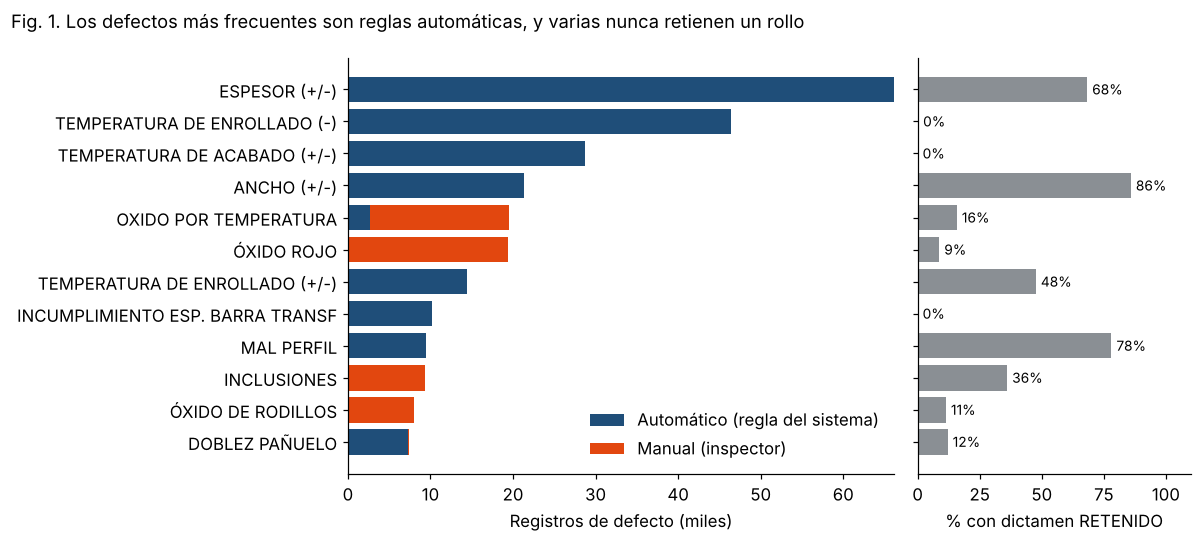

In [7]:
g = (D.groupby('d')
       .agg(n=('a', 'size'), auto=('a', 'mean'), ret=('ret', 'mean'))
       .sort_values('n', ascending=False).head(12)[::-1])

fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharey=True, gridspec_kw={'width_ratios': [2, 1]})
ax[0].barh(g.index, g.n * g.auto / 1000, color=COLORES['azul'], label='Automático (regla del sistema)')
ax[0].barh(g.index, g.n * (1 - g.auto) / 1000, left=g.n * g.auto / 1000, color=COLORES['naranja'], label='Manual (inspector)')
ax[0].set_xlabel('Registros de defecto (miles)')
ax[0].legend(loc='lower right')

ax[1].barh(g.index, g.ret * 100, color=COLORES['gris'])
ax[1].set_xlabel('% con dictamen RETENIDO')
ax[1].set_xlim(0, 110)
for i, v in enumerate(g.ret * 100):
    ax[1].text(v + 2, i, f'{v:.0f}%', va='center', fontsize=9)

fig.suptitle('Fig. 1. Los defectos más frecuentes son reglas automáticas, y varias nunca retienen un rollo',
             x=0.01, ha='left', fontsize=12)
fig.tight_layout()
guardar(fig, 'fig1_calidad')
plt.show()

**Cómo leerla.** Izquierda: cuántos registros tiene cada defecto y qué parte es automática (azul) o de inspector (naranja). Derecha: qué porcentaje de esos registros retiene el rollo.

**Qué vemos.** Los cuatro defectos más frecuentes son casi totalmente automáticos. Algunos, como TEMPERATURA DE ACABADO e INCUMPLIMIENTO ESP. BARRA TRANSF., nunca retienen un rollo: son avisos, no calidad. Los defectos de inspector (óxidos, inclusiones) son minoría y retienen poco.

## Implicaciones para el análisis
1. **Resultado:** la calidad de entrada al Skinpass se mide con mediciones físicas continuas (Corona Salida, Acuñamiento Salida, corona relativa), no con el Dictamen.
2. **Variables prohibidas como explicativas:** Dictamen, Resolución, Calidad Sugerida, Defecto, Causa, Observaciones y Fecha de Registro (se generan después del resultado).
3. MAL PERFIL, ESPESOR, ANCHO y los defectos térmicos automáticos no pueden ser resultado si la medición que los define está entre las explicativas.
4. Los defectos de inspector (óxido rojo, inclusiones) son los únicos candidatos a resultado independiente, con la salvedad del juicio humano.